In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dry beans dataset
file_path = r'C:\Users\sumit\DATA_SCIENCE\ASSIGNMENTS & PROJECTS\Dry Beans Classification\Dry_Beans_Dataset.xlsx'
df = pd.read_excel(file_path)

# Display the first few rows of the dataset
display(df.head())

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [86]:
# Display the summary information about the dataframe
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [87]:
# Display the statistical summary of numerical features
display(df.describe())

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


### 1. Feature Distributions (Histograms & Boxplots)

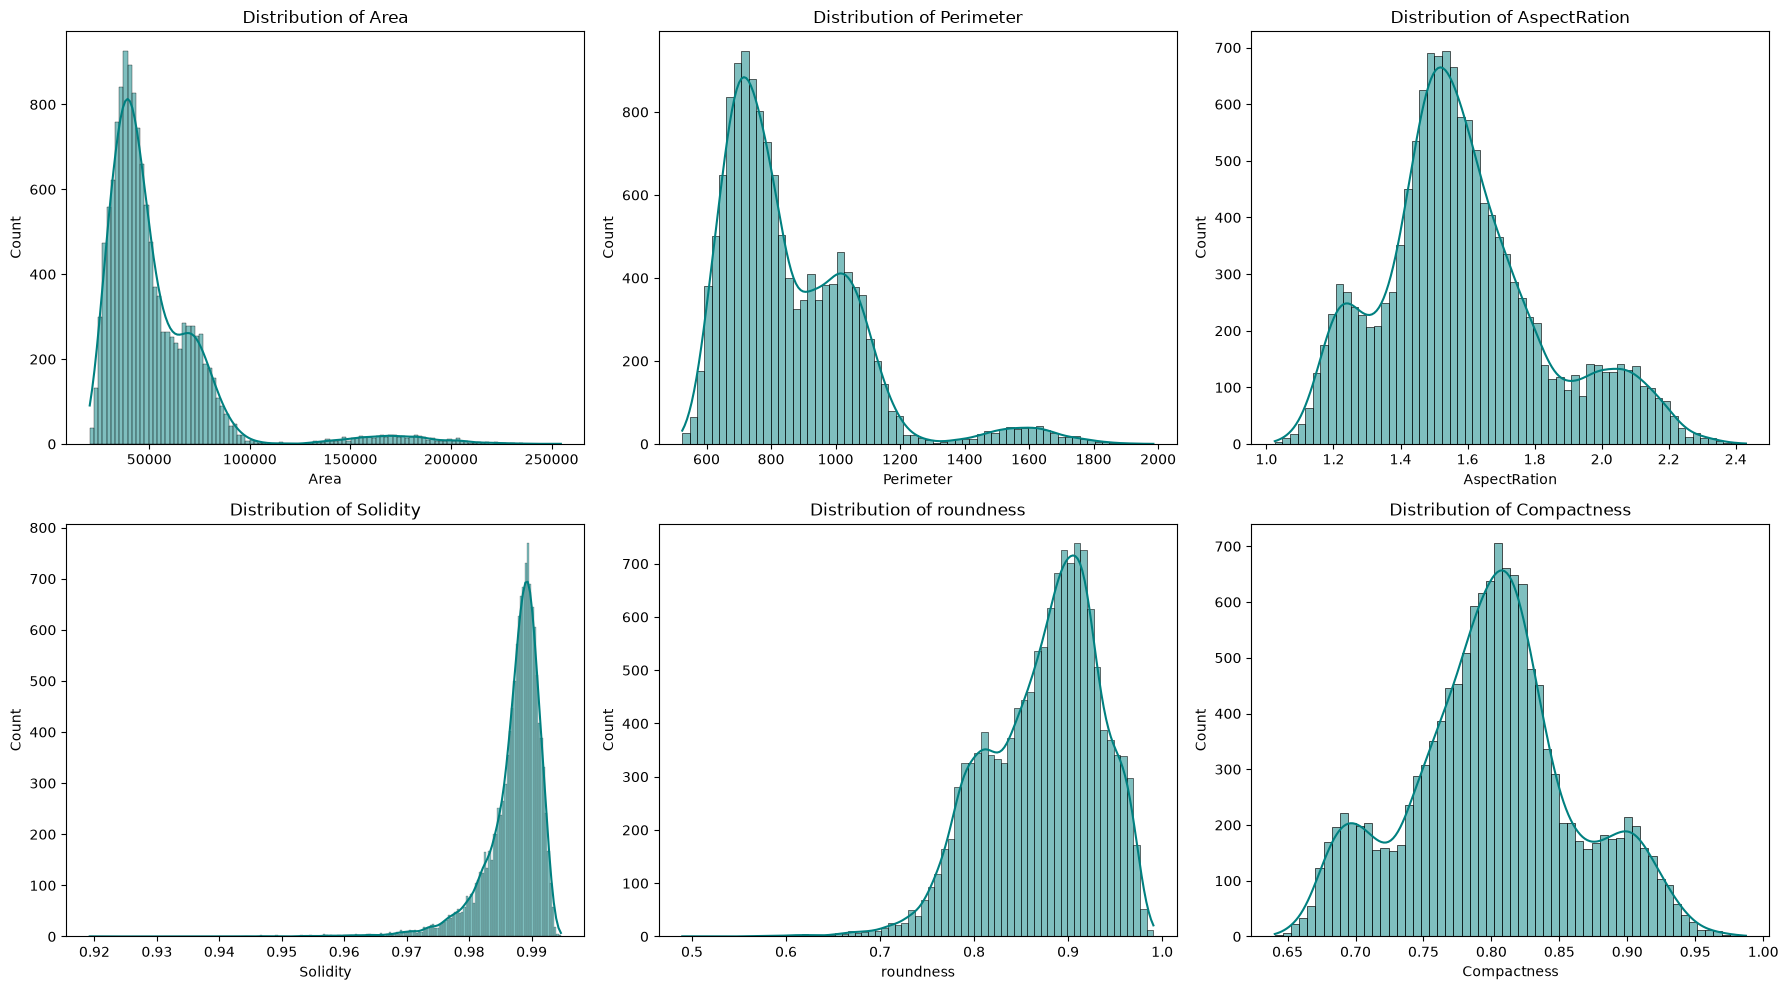

In [88]:
# Select a few key numerical features to visualize distributions
key_features = ['Area', 'Perimeter', 'AspectRation', 'Solidity', 'roundness', 'Compactness']

# Plot Histograms
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, col in enumerate(key_features):
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal')
    axes[i].set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

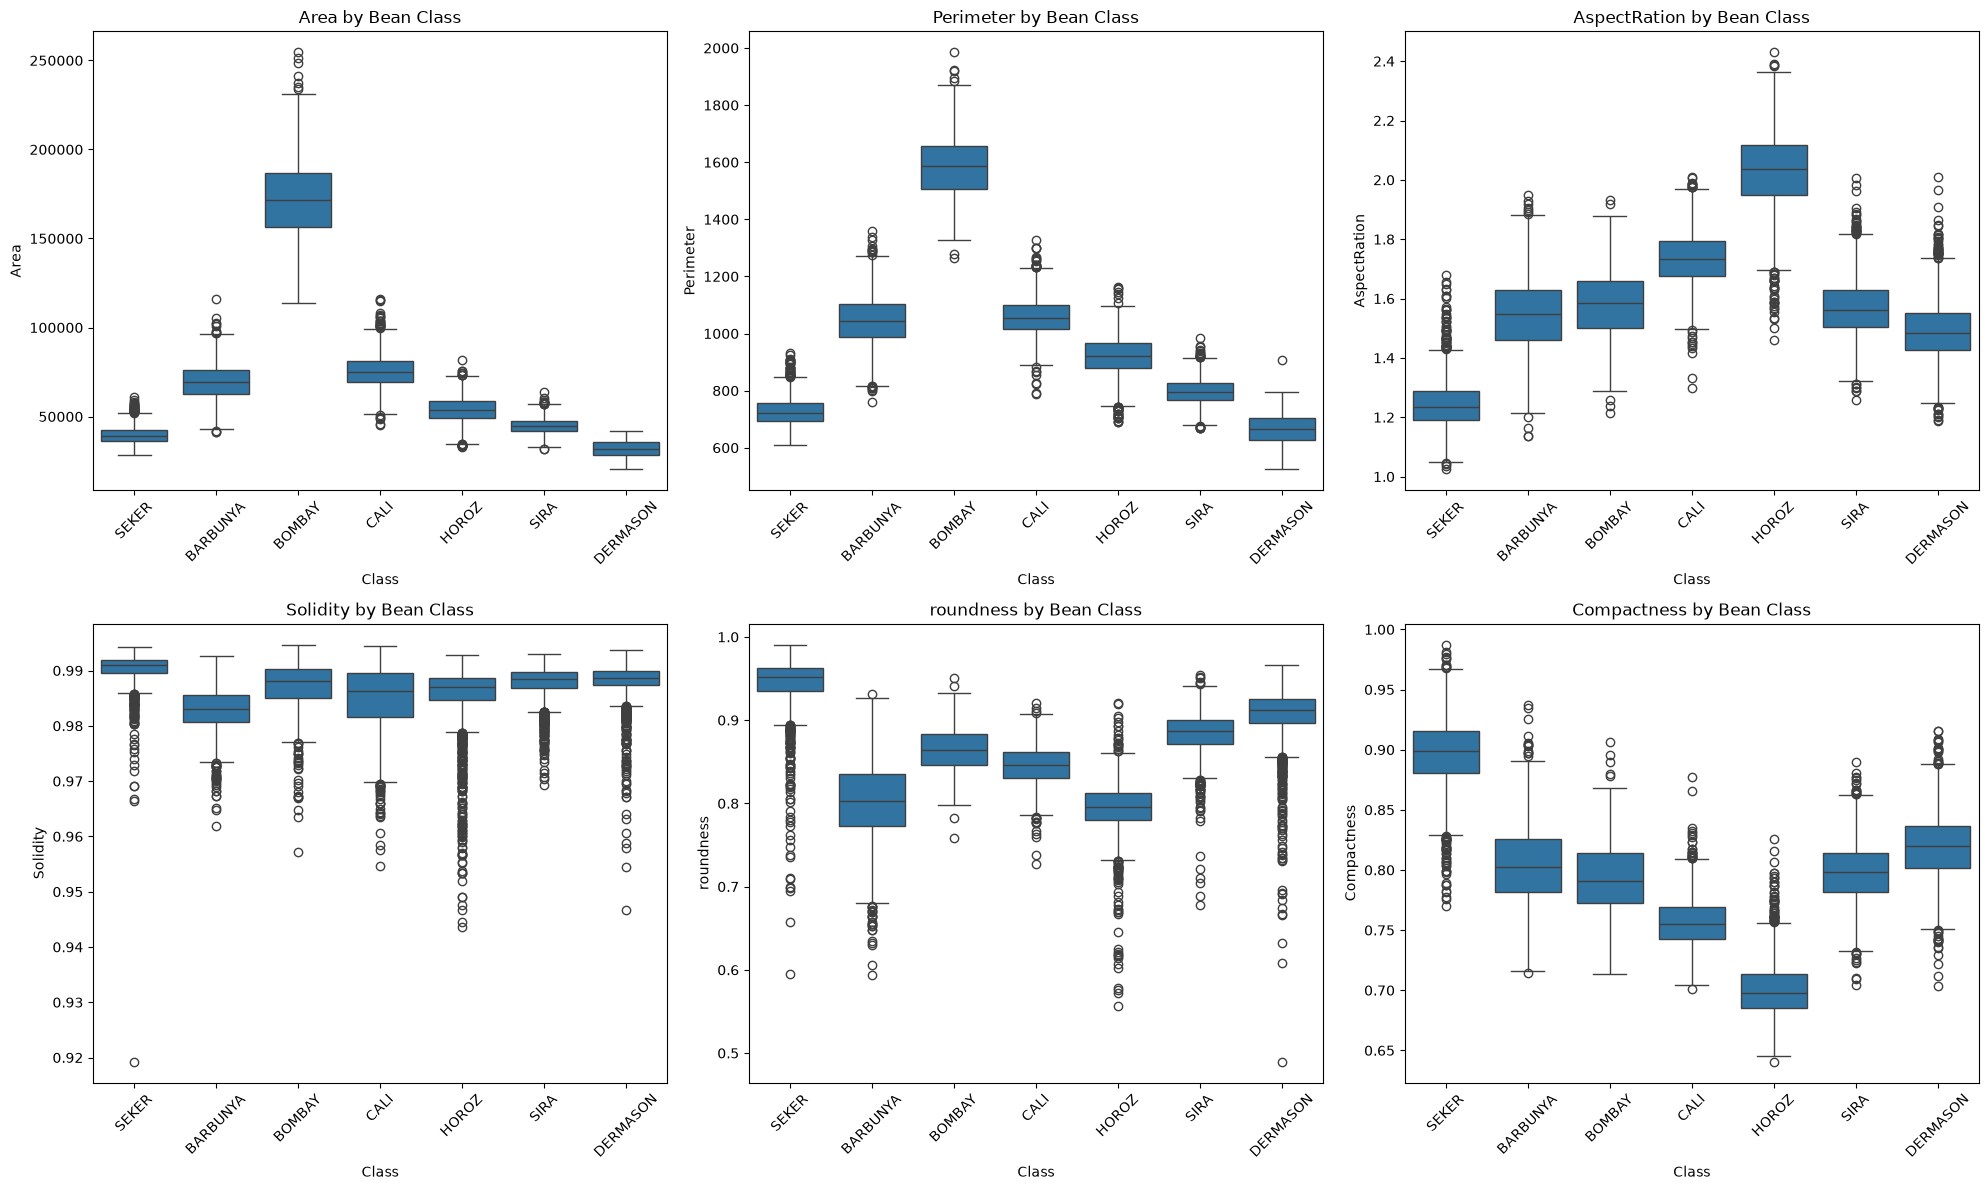

In [89]:
# Plot Boxplots to identify outliers
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()
for i, col in enumerate(key_features):
    sns.boxplot(x='Class', y=col, data=df, ax=axes[i])
    axes[i].set_title(f'{col} by Bean Class')
    axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### 2. Class Distribution (Class Imbalance Check)

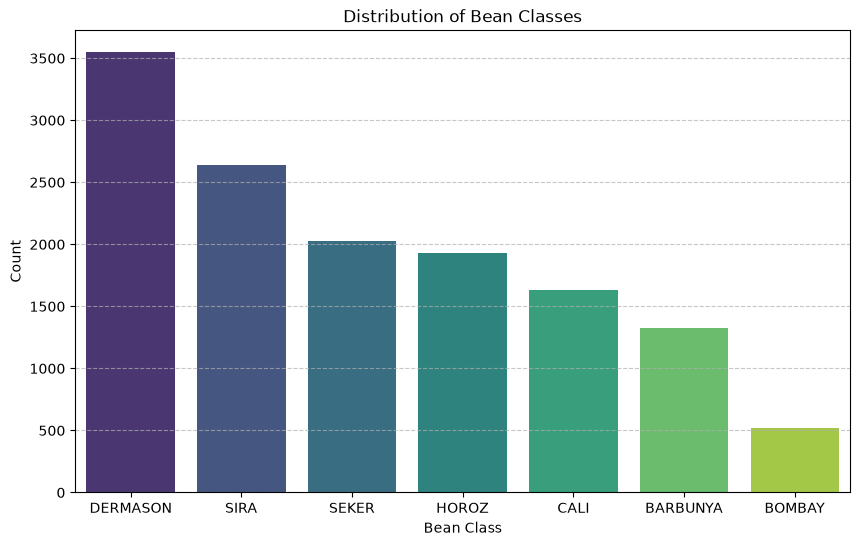

,Count,Percentage (%)
Class,,
DERMASON,3546,26.052458
SIRA,2636,19.366689
SEKER,2027,14.892366
HOROZ,1928,14.165014
CALI,1630,11.975608
BARBUNYA,1322,9.712732
BOMBAY,522,3.835133


In [90]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Class', data=df, order=df['Class'].value_counts().index, palette='viridis')
plt.title('Distribution of Bean Classes')
plt.xlabel('Bean Class')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Print value counts and percentages
class_counts = df['Class'].value_counts()
class_pcts = df['Class'].value_counts(normalize=True) * 100
display(pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_pcts}))

### 3. Feature Correlations (Heatmap)

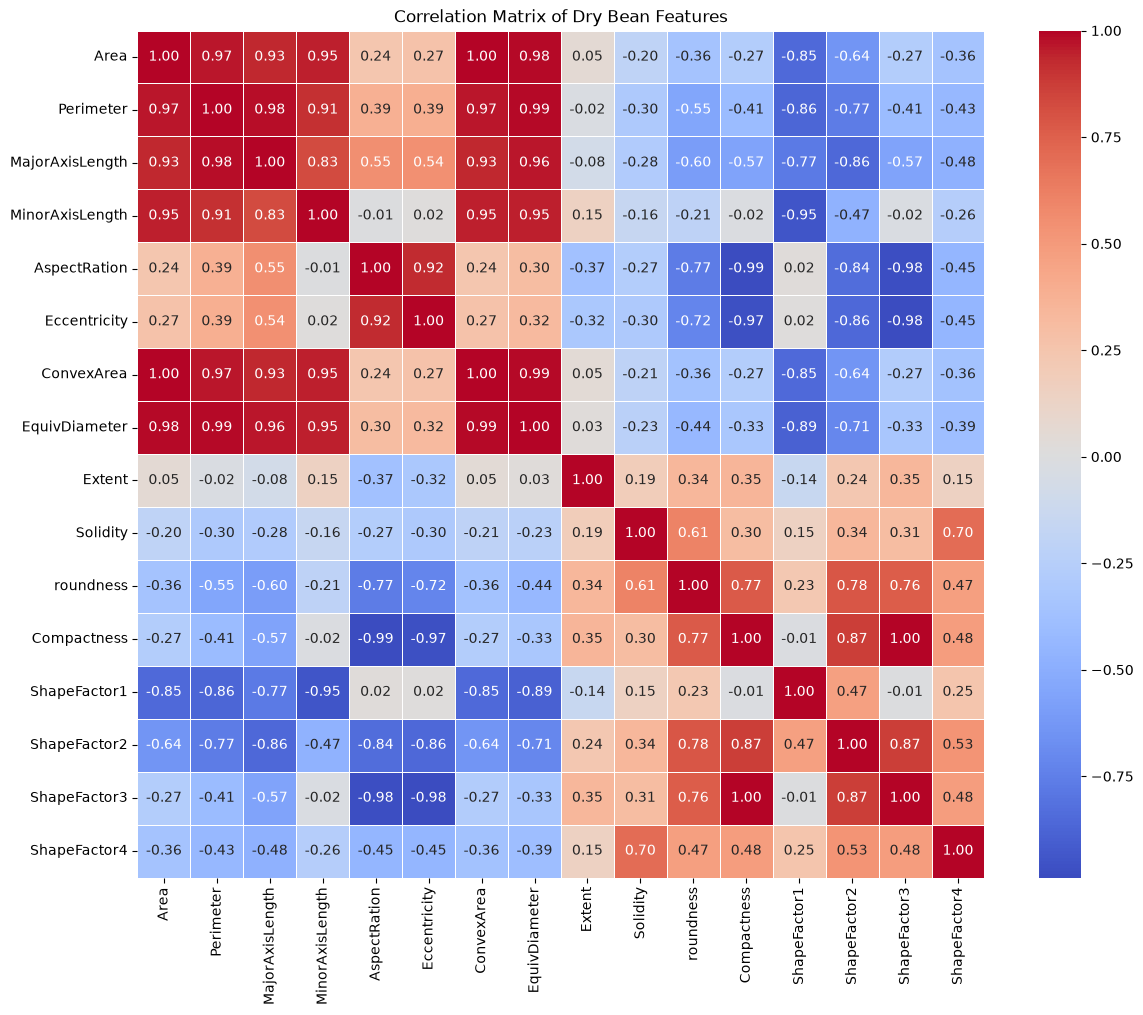

In [91]:
plt.figure(figsize=(14, 11))
# Calculate correlation only on numerical columns
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Dry Bean Features')
plt.show()

### 4. Multivariate Relationships (Pairplot)

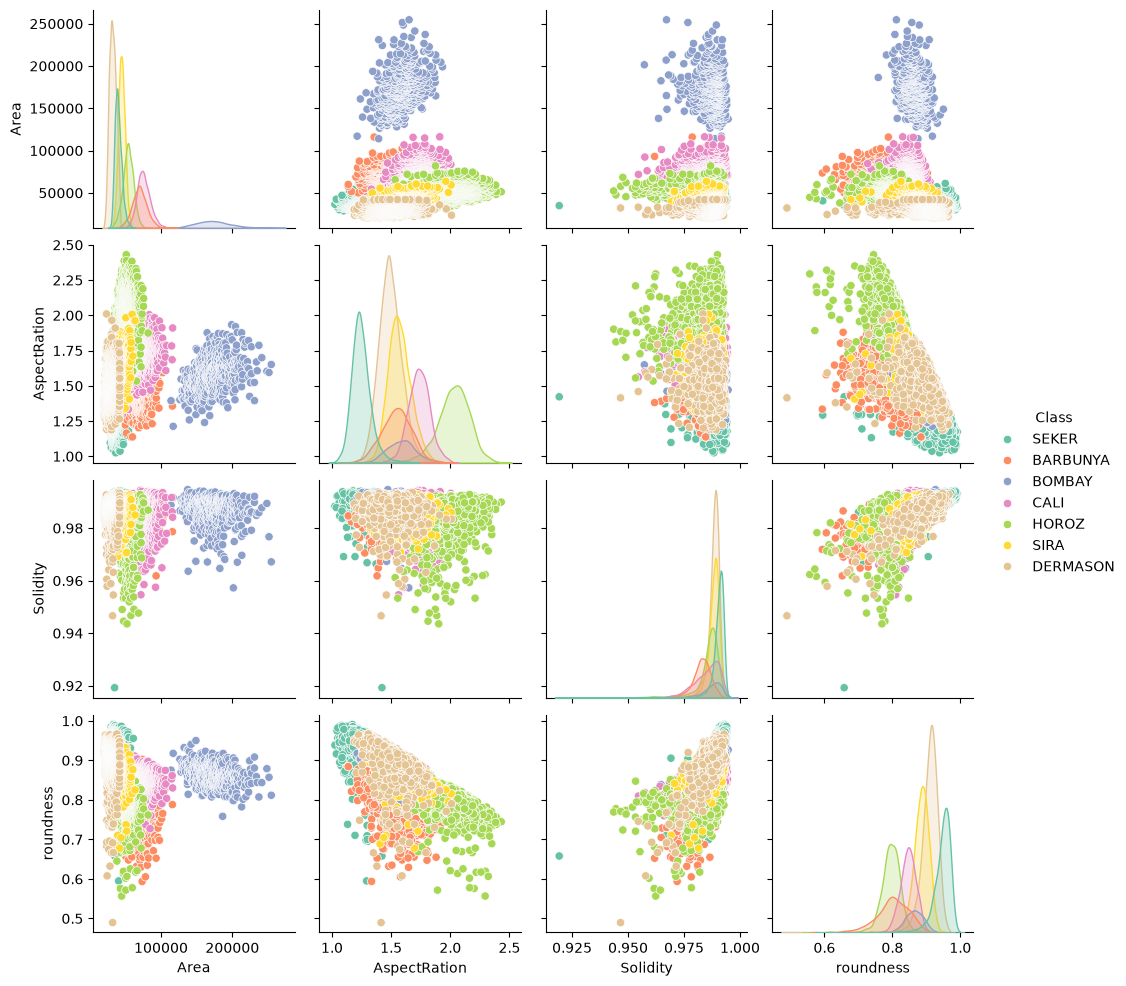

In [92]:
# Plotting a subset of features in a pairplot to maintain readability and performance
selected_subset = ['Area', 'AspectRation', 'Solidity', 'roundness', 'Class']
sns.pairplot(df[selected_subset], hue='Class', palette='Set2')
plt.show()

### Missing Values and Outlier Treatment

In [93]:
# 1. Check for missing values
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0] if missing_values.any() else "No missing values found!")

# 2. Detect outliers using the IQR method
numeric_cols = df.select_dtypes(include=[np.number]).columns
outliers_summary = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count outliers
    num_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    pct_outliers = (num_outliers / len(df)) * 100
    outliers_summary[col] = {'Outlier Count': num_outliers, 'Percentage (%)': round(pct_outliers, 2)}

display(pd.DataFrame(outliers_summary).T)

Missing values per column:
No missing values found!


,Outlier Count,Percentage (%)
Area,551.0,4.05
Perimeter,500.0,3.67
MajorAxisLength,379.0,2.78
MinorAxisLength,569.0,4.18
AspectRation,473.0,3.48
Eccentricity,843.0,6.19
ConvexArea,550.0,4.04
EquivDiameter,526.0,3.86
Extent,275.0,2.02
Solidity,778.0,5.72


### Outlier Treatment

In [94]:
# Create a copy of the dataframe to perform treatment
df_cleaned = df.copy()

# Apply 1st and 99th percentile capping on numerical columns
for col in numeric_cols:
    lower_limit = df_cleaned[col].quantile(0.01)
    upper_limit = df_cleaned[col].quantile(0.99)
    
    # Cap values
    df_cleaned[col] = np.clip(df_cleaned[col], lower_limit, upper_limit)

print("Outliers successfully capped at the 1st and 99th percentiles!")
print("Shape of dataset before treatment:", df.shape)
print("Shape of dataset after treatment:", df_cleaned.shape)

Outliers successfully capped at the 1st and 99th percentiles!
Shape of dataset before treatment: (13611, 17)
Shape of dataset after treatment: (13611, 17)


### Feature Engineering & Preprocessing

In [95]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# 1. Encode target variable 'Class'
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df_cleaned['Class'])
print("Encoded target classes successfully.")
print("Mapping of classes:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Encoded target classes successfully.
Mapping of classes: {'BARBUNYA': np.int64(0), 'BOMBAY': np.int64(1), 'CALI': np.int64(2), 'DERMASON': np.int64(3), 'HOROZ': np.int64(4), 'SEKER': np.int64(5), 'SIRA': np.int64(6)}


In [96]:
# 2. Check skewness of numerical features
skewness = df_cleaned[numeric_cols].skew()
print("Original Feature Skewness:")
display(skewness.to_frame(name='Skewness'))

# Identify highly skewed features (skew > 0.75 or skew < -0.75)
highly_skewed = skewness[abs(skewness) > 0.75].index
print("\nHighly skewed features to be transformed:", list(highly_skewed))

# Apply log1p transformation to reduce skewness on selected features
df_transformed = df_cleaned.copy()
for col in highly_skewed:
    # Shift values if they contain negative numbers, but all indicators here are positive
    df_transformed[col] = np.log1p(df_transformed[col])

print("\nSkewness after transformation:")
display(df_transformed[highly_skewed].skew().to_frame(name='Skewness (Transformed)'))

Original Feature Skewness:


,Skewness
Area,2.761630
Perimeter,1.531413
MajorAxisLength,1.259383
MinorAxisLength,2.136345
AspectRation,0.562536
Eccentricity,-0.932701
ConvexArea,2.746874
EquivDiameter,1.852416
Extent,-0.862882
Solidity,-1.644115



Highly skewed features to be transformed: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'ShapeFactor4']

Skewness after transformation:


,Skewness (Transformed)
Area,1.039305
Perimeter,0.815633
MajorAxisLength,0.606643
MinorAxisLength,1.277944
Eccentricity,-1.078865
ConvexArea,1.033535
EquivDiameter,1.041862
Extent,-0.935753
Solidity,-1.652526
ShapeFactor4,-1.826407


In [97]:
# 3. Scale numerical features using StandardScaler
scaler = StandardScaler()
X_numerical_scaled = scaler.fit_transform(df_transformed[numeric_cols])

# Create final feature matrix X
X = pd.DataFrame(X_numerical_scaled, columns=numeric_cols)
print("Numerical features scaled successfully with StandardScaler.")

Numerical features scaled successfully with StandardScaler.


In [98]:
# 4. Stratified Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print("Stratified Train-Test Split successfully executed.")
print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Test set shape: X_test={X_test.shape}, y_test={y_test.shape}")

Stratified Train-Test Split successfully executed.
Training set shape: X_train=(10888, 16), y_train=(10888,)
Test set shape: X_test=(2723, 16), y_test=(2723,)


## Model Building & Cross-Validation
We will train several standard classifiers and evaluate their baseline cross-validation performance:
1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. K-Nearest Neighbors (KNN)
5. Support Vector Machine (SVM)
6. Naive Bayes (Gaussian)
7. Ensemble Learning (Gradient Boosting)

In [99]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
import warnings

warnings.filterwarnings('ignore')

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Support Vector Machine': SVC(random_state=42),
    'Gaussian Naive Bayes': GaussianNB(),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# Evaluate each model using 5-fold Cross-Validation
cv_results = {}
print("Evaluating baseline classifiers with 5-fold Cross-Validation...\n")
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:25}: Mean Accuracy = {scores.mean():.4f} (+/- {scores.std():.4f})")

Evaluating baseline classifiers with 5-fold Cross-Validation...

Logistic Regression      : Mean Accuracy = 0.9250 (+/- 0.0063)
Decision Tree            : Mean Accuracy = 0.8953 (+/- 0.0055)
Random Forest            : Mean Accuracy = 0.9245 (+/- 0.0042)
K-Nearest Neighbors      : Mean Accuracy = 0.9195 (+/- 0.0072)
Support Vector Machine   : Mean Accuracy = 0.9316 (+/- 0.0052)
Gaussian Naive Bayes     : Mean Accuracy = 0.8963 (+/- 0.0056)
Gradient Boosting        : Mean Accuracy = 0.9263 (+/- 0.0066)


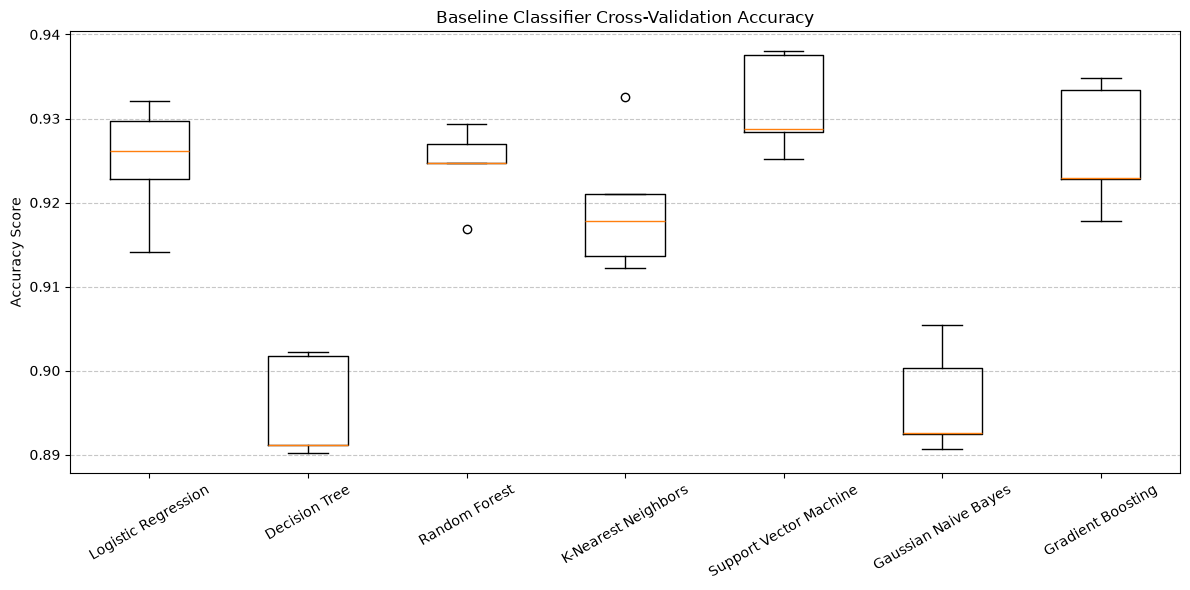

In [100]:
# Visualize Cross-Validation Results
plt.figure(figsize=(12, 6))
plt.boxplot(cv_results.values(), tick_labels=cv_results.keys())
plt.title('Baseline Classifier Cross-Validation Accuracy')
plt.ylabel('Accuracy Score')
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Model Optimization & Evaluation
We will use `GridSearchCV` to optimize the hyperparameters of our best-performing baseline model, the **Support Vector Machine (SVM)**.

In [101]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Define the hyperparameter grid for SVM
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto', 0.1, 0.01],
    'kernel': ['rbf']
}

# Initialize GridSearchCV
grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# Fit the grid search on the training data
print("Optimizing Support Vector Machine (SVM)...")
grid_search.fit(X_train, y_train)

# Print the best parameters and cross-validation score
print(f"\nBest Parameters found: {grid_search.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

Optimizing Support Vector Machine (SVM)...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best Parameters found: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 0.9345



--- Final Test Set Evaluation (Optimized SVM) ---
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.91      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.95      0.94       326
    DERMASON       0.91      0.93      0.92       709
       HOROZ       0.97      0.95      0.96       386
       SEKER       0.95      0.96      0.95       406
        SIRA       0.88      0.86      0.87       527

    accuracy                           0.93      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.93      0.93      0.93      2723



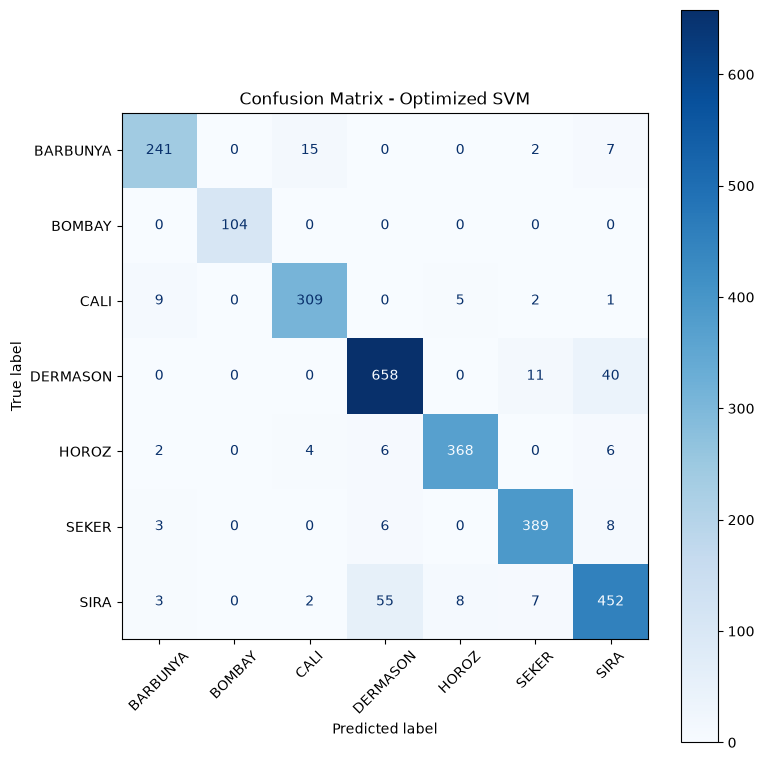

In [102]:
# Evaluate the final optimized model on the unseen test set
best_svm = grid_search.best_estimator_
y_pred = best_svm.predict(X_test)

# Print the classification report
print("\n--- Final Test Set Evaluation (Optimized SVM) ---")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(8, 8))
cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred, 
    display_labels=label_encoder.classes_, 
    cmap='Blues', 
    ax=ax, 
    xticks_rotation=45
)
plt.title('Confusion Matrix - Optimized SVM')
plt.tight_layout()
plt.show()

### Handling Class Imbalance with SMOTE

In [103]:
%pip install -q imbalanced-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [104]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Check original class distribution in training set
print("Original training class distribution:", Counter(y_train))

# Apply SMOTE to training data
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Resampled training class distribution:", Counter(y_train_res))

Original training class distribution: Counter({np.int64(3): 2837, np.int64(6): 2109, np.int64(5): 1621, np.int64(4): 1542, np.int64(2): 1304, np.int64(0): 1057, np.int64(1): 418})
Resampled training class distribution: Counter({np.int64(5): 2837, np.int64(4): 2837, np.int64(2): 2837, np.int64(6): 2837, np.int64(3): 2837, np.int64(0): 2837, np.int64(1): 2837})



--- Test Set Evaluation (SVM with SMOTE Balanced Data) ---
              precision    recall  f1-score   support

    BARBUNYA       0.91      0.92      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.92      0.92      0.92       709
       HOROZ       0.97      0.95      0.96       386
       SEKER       0.93      0.96      0.95       406
        SIRA       0.88      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.92      0.92      0.92      2723



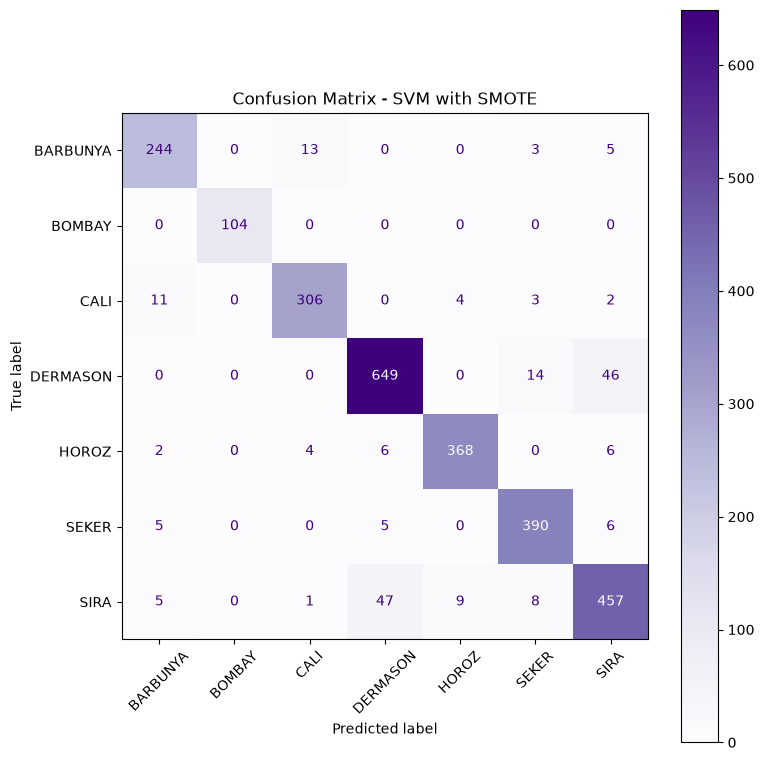

In [105]:
# Retrain the optimized SVM model with the balanced training data
svm_balanced = SVC(C=10, gamma=0.1, kernel='rbf', random_state=42)
svm_balanced.fit(X_train_res, y_train_res)

# Evaluate on the holdout validation set
y_pred_balanced = svm_balanced.predict(X_test)

print("\n--- Test Set Evaluation (SVM with SMOTE Balanced Data) ---")
print(classification_report(y_test, y_pred_balanced, target_names=label_encoder.classes_))

# Plot the new confusion matrix
fig, ax = plt.subplots(figsize=(8, 8))
cm_display_bal = ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_pred_balanced, 
    display_labels=label_encoder.classes_, 
    cmap='Purples', 
    ax=ax, 
    xticks_rotation=45
)
plt.title('Confusion Matrix - SVM with SMOTE')
plt.tight_layout()
plt.show()

### Model Evaluation & Overfitting Check

In [106]:
from sklearn.metrics import accuracy_score, classification_report

# Predict on training and test sets
y_train_pred = best_svm.predict(X_train)
y_test_pred = best_svm.predict(X_test)

# Calculate Accuracies
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("--- Accuracy Comparison ---")
print(f"Training Accuracy: {train_acc * 100:.2f}%")
print(f"Test Accuracy:     {test_acc * 100:.2f}%")
print(f"Difference:        {(train_acc - test_acc) * 100:.2f}%")

--- Accuracy Comparison ---
Training Accuracy: 94.34%
Test Accuracy:     92.58%
Difference:        1.76%


In [107]:
print("\n--- Training Set Classification Report ---")
print(classification_report(y_train, y_train_pred, target_names=label_encoder.classes_))

print("\n--- Test Set Classification Report ---")
print(classification_report(y_test, y_test_pred, target_names=label_encoder.classes_))


--- Training Set Classification Report ---
              precision    recall  f1-score   support

    BARBUNYA       0.97      0.95      0.96      1057
      BOMBAY       1.00      1.00      1.00       418
        CALI       0.96      0.96      0.96      1304
    DERMASON       0.92      0.95      0.93      2837
       HOROZ       0.97      0.96      0.97      1542
       SEKER       0.97      0.96      0.96      1621
        SIRA       0.91      0.88      0.89      2109

    accuracy                           0.94     10888
   macro avg       0.96      0.95      0.95     10888
weighted avg       0.94      0.94      0.94     10888


--- Test Set Classification Report ---
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.91      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.95      0.94       326
    DERMASON       0.91      0.93      0.92       709
       HOROZ       0.97      0.95      0.96     

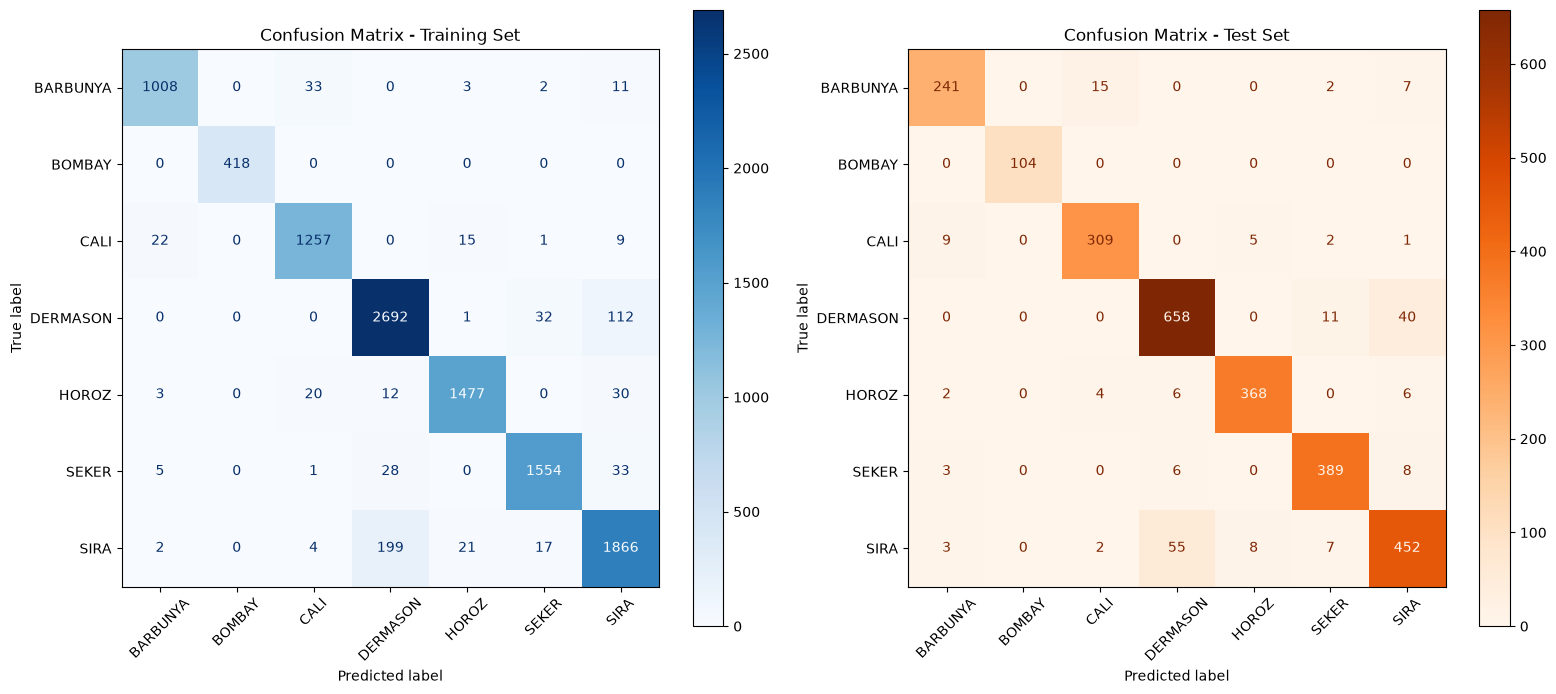

In [108]:
# Compare Train vs. Test Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

ConfusionMatrixDisplay.from_predictions(
    y_train, 
    y_train_pred, 
    display_labels=label_encoder.classes_, 
    cmap='Blues', 
    ax=axes[0], 
    xticks_rotation=45
)
axes[0].set_title('Confusion Matrix - Training Set')

ConfusionMatrixDisplay.from_predictions(
    y_test, 
    y_test_pred, 
    display_labels=label_encoder.classes_, 
    cmap='Oranges', 
    ax=axes[1], 
    xticks_rotation=45
)
axes[1].set_title('Confusion Matrix - Test Set')

plt.tight_layout()
plt.show()

### Hyperparameter Tuning on Alternative Top Model (Random Forest)

In [109]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid for Random Forest
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'criterion': ['gini', 'entropy']
}

# Initialize GridSearchCV for Random Forest
rf_grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Fit the grid search on the training data
print("Optimizing Random Forest Classifier...")
rf_grid_search.fit(X_train, y_train)

# Print the best parameters and cross-validation score
print(f"\nBest Random Forest Parameters: {rf_grid_search.best_params_}")
print(f"Best Cross-Validation Accuracy: {rf_grid_search.best_score_:.4f}")

Optimizing Random Forest Classifier...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Random Forest Parameters: {'criterion': 'gini', 'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.9262


In [110]:
from sklearn.metrics import accuracy_score, classification_report

# Evaluate the final optimized Random Forest on the unseen test set
best_rf = rf_grid_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)
rf_test_acc = accuracy_score(y_test, y_pred_rf)

# Retrieve SVM baseline and optimized metrics for comparison
svm_baseline_acc = 0.9316
svm_optimized_acc = 0.9345
rf_baseline_acc = 0.9245

# Print Comparison Summary
print("=== Hyperparameter Tuning & Performance Summary ===\n")
print(f"Support Vector Machine:")
print(f"  - Baseline CV Accuracy:   {svm_baseline_acc:.4f}")
print(f"  - Best Tuned CV Accuracy: {grid_search.best_score_:.4f} (Best Params: {grid_search.best_params_})")
print(f"  - Improvement:            +{((grid_search.best_score_ - svm_baseline_acc) * 100):.2f}%\n")

print(f"Random Forest Classifier:")
print(f"  - Baseline CV Accuracy:   {rf_baseline_acc:.4f}")
print(f"  - Best Tuned CV Accuracy: {rf_grid_search.best_score_:.4f} (Best Params: {rf_grid_search.best_params_})")
print(f"  - Improvement:            +{((rf_grid_search.best_score_ - rf_baseline_acc) * 100):.2f}%\n")

print(f"Final Test Accuracy of Best SVM Model:           {test_acc * 100:.2f}%")
print(f"Final Test Accuracy of Best Random Forest Model: {rf_test_acc * 100:.2f}%")

=== Hyperparameter Tuning & Performance Summary ===

Support Vector Machine:
  - Baseline CV Accuracy:   0.9316
  - Best Tuned CV Accuracy: 0.9345 (Best Params: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'})
  - Improvement:            +0.29%

Random Forest Classifier:
  - Baseline CV Accuracy:   0.9245
  - Best Tuned CV Accuracy: 0.9262 (Best Params: {'criterion': 'gini', 'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100})
  - Improvement:            +0.17%

Final Test Accuracy of Best SVM Model:           92.58%
Final Test Accuracy of Best Random Forest Model: 91.99%


### 9. Model Comparison & Final Leaderboard

In [111]:
from sklearn.metrics import f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

# 1. Load the dry beans dataset
file_path = 'Dry_Beans_Dataset.xlsx'
df = pd.read_excel(file_path)

# 2. Re-apply 1st and 99th percentile capping on numerical columns to treat outliers
numeric_cols = df.select_dtypes(include=[np.number]).columns
df_cleaned = df.copy()
for col in numeric_cols:
    lower_limit = df_cleaned[col].quantile(0.01)
    upper_limit = df_cleaned[col].quantile(0.99)
    df_cleaned[col] = np.clip(df_cleaned[col], lower_limit, upper_limit)

# 3. Encode target variable 'Class'
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df_cleaned['Class'])

# 4. Transform highly skewed features and scale them
skewness = df_cleaned[numeric_cols].skew()
highly_skewed = skewness[abs(skewness) > 0.75].index
df_transformed = df_cleaned.copy()
for col in highly_skewed:
    df_transformed[col] = np.log1p(df_transformed[col])

scaler = StandardScaler()
X_numerical_scaled = scaler.fit_transform(df_transformed[numeric_cols])
X = pd.DataFrame(X_numerical_scaled, columns=numeric_cols)

# 5. Execute stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# 6. Define the baseline models
baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Support Vector Machine': SVC(random_state=42),
    'Gaussian Naive Bayes': GaussianNB(),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# 7. Define the optimized estimators based on the tuning results
opt_svm = SVC(C=10, gamma=0.1, kernel='rbf', random_state=42)
opt_rf = RandomForestClassifier(criterion='gini', max_depth=20, min_samples_split=2, n_estimators=100, random_state=42, n_jobs=-1)

# Initialize lists to gather final records
records = []

# Calculate metrics for each baseline classifier
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    tr_pred = model.predict(X_train)
    te_pred = model.predict(X_test)
    
    tr_acc = accuracy_score(y_train, tr_pred)
    te_acc = accuracy_score(y_test, te_pred)
    te_f1 = f1_score(y_test, te_pred, average='weighted')
    
    overfitting = "Yes" if (tr_acc - te_acc) > 0.04 else "No"
    
    records.append({
        'Model': f"{name} (Baseline)",
        'Train Accuracy': f"{tr_acc:.4f}",
        'Test Accuracy': f"{te_acc:.4f}",
        'F1 Score (Weighted)': f"{te_f1:.4f}",
        'Overfitting (Y/N)': overfitting
    })

# Calculate metrics for tuned models
for opt_name, opt_model in [('Optimized SVM', opt_svm), ('Optimized Random Forest', opt_rf)]:
    opt_model.fit(X_train, y_train)
    tr_pred = opt_model.predict(X_train)
    te_pred = opt_model.predict(X_test)
    
    tr_acc = accuracy_score(y_train, tr_pred)
    te_acc = accuracy_score(y_test, te_pred)
    te_f1 = f1_score(y_test, te_pred, average='weighted')
    
    overfitting = "Yes" if (tr_acc - te_acc) > 0.04 else "No"
    
    records.append({
        'Model': opt_name,
        'Train Accuracy': f"{tr_acc:.4f}",
        'Test Accuracy': f"{te_acc:.4f}",
        'F1 Score (Weighted)': f"{te_f1:.4f}",
        'Overfitting (Y/N)': overfitting
    })

# Create DataFrame
comparison_df = pd.DataFrame(records)

# Identify the best model based on F1 Score
comparison_df['F1 Score (Weighted) Num'] = comparison_df['F1 Score (Weighted)'].astype(float)
best_idx = comparison_df['F1 Score (Weighted) Num'].idxmax()
best_model_row = comparison_df.loc[best_idx].copy()

# Clean comparison dataframe
comparison_df = comparison_df.drop(columns=['F1 Score (Weighted) Num'])

display(comparison_df)

print("\n================ CHAMPION MODEL ===================")
print(f"Best Model:          {best_model_row['Model']}")
print(f"Test Accuracy:       {float(best_model_row['Test Accuracy'])*100:.2f}%")
print(f"F1 Score (Weighted): {float(best_model_row['F1 Score (Weighted)'])*100:.2f}%")
print(f"Overfitting?         {best_model_row['Overfitting (Y/N)']}")
print("====================================================")

,Model,Train Accuracy,Test Accuracy,F1 Score (Weighted),Overfitting (Y/N)
0,Logistic Regression (Baseline),0.9265,0.9214,0.9216,No
1,Decision Tree (Baseline),1.0000,0.8920,0.8916,Yes
2,Random Forest (Baseline),1.0000,0.9221,0.9221,Yes
3,K-Nearest Neighbors (Baseline),0.9430,0.9163,0.9163,No
4,Support Vector Machine (Baseline),0.9342,0.9243,0.9244,No
5,Gaussian Naive Bayes (Baseline),0.8967,0.8972,0.8974,No
6,Gradient Boosting (Baseline),0.9641,0.9229,0.9229,Yes
7,Optimized SVM,0.9434,0.9258,0.9257,No
8,Optimized Random Forest,0.9984,0.9199,0.9199,Yes



================ CHAMPION MODEL ===================
Best Model:          Optimized SVM
Test Accuracy:       92.58%
F1 Score (Weighted): 92.57%
Overfitting?         No
